# Kode 3.1 Statistik dan histogram untuk diagnosis 

In [6]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src" / "utils_cv.py").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))


teh_041.png {'rerata': 166.0, 'simpangan_baku': 29.8, 'min': 65, 'maks': 220, 'persen_gelap': 0.0, 'persen_terang': 0.1}
teh_042.png {'rerata': 132.0, 'simpangan_baku': 45.6, 'min': 13, 'maks': 191, 'persen_gelap': 9.0, 'persen_terang': 0.0}
teh_043.png {'rerata': 213.3, 'simpangan_baku': 26.1, 'min': 135, 'maks': 253, 'persen_gelap': 0.0, 'persen_terang': 77.5}
teh_044.png {'rerata': 153.2, 'simpangan_baku': 15.7, 'min': 94, 'maks': 196, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 128.0, 'simpangan_baku': 58.3, 'min': 25, 'maks': 247, 'persen_gelap': 2.7, 'persen_terang': 14.2}


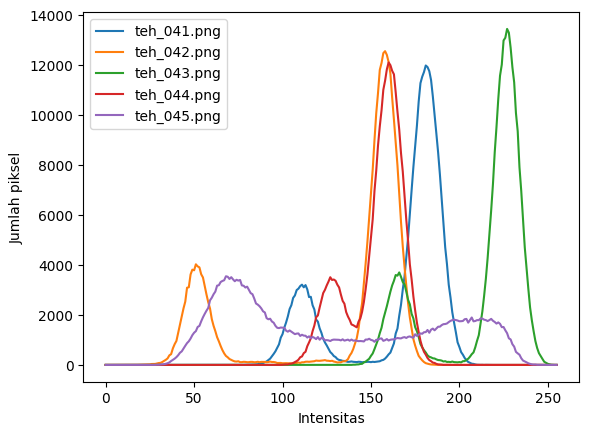

In [7]:
import cv2 
import matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak, statistik 

for nama in ["teh_041.png", "teh_042.png", "teh_043.png", 
"teh_044.png", "teh_045.png"]: 
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), 
    cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend() 
plt.savefig("../hasil/b3_histogram_5kondisi.png") 

# Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE 

In [8]:
import numpy as np

nama = "teh_045.png"                 # kondisi bayangan 
img = baca(f"../data/sintetis/citra/{nama}") 
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0) 
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0) 
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
  
def gamma_lut(g): 
    lut = np.array([255 * (i / 255) ** g for i in range(256)]) 
    return lut.clip(0, 255).astype(np.uint8) 
  
rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem 
hasil = { 
    "asli": gray, 
    "negatif": 255 - gray, 
    "cerah+50": cv2.add(gray, 50), 
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40), 
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 
                      0, 255).astype(np.uint8), 
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)), 
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)), 
    "ekualisasi": cv2.equalizeHist(gray), 
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, 
                             tileGridSize=(8, 8)).apply(gray), 
} 
for nm, c in hasil.items(): 
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} " 
          f"sigma={c.std():.1f}") 


asli       KB=2.16 sigma=58.3
negatif    KB=2.16 sigma=58.3
cerah+50   KB=2.16 sigma=55.5
kontras    KB=2.16 sigma=80.4
regang     KB=2.26 sigma=82.7
gamma0.5   KB=1.88 sigma=41.7
gamma1.8   KB=2.69 sigma=63.8
ekualisasi KB=1.75 sigma=73.4
CLAHE      KB=2.71 sigma=48.9


# Kode 3.3 Panel V vs BGR


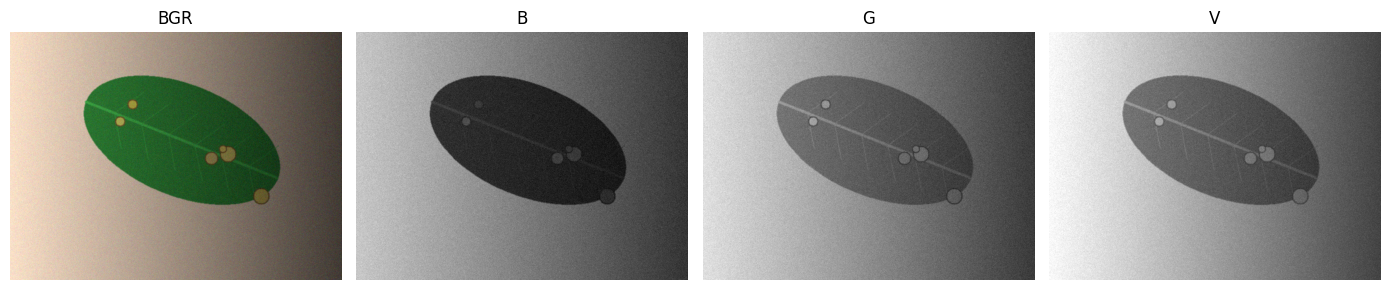

In [9]:
# Bandingkan panel kanal V (HSV) dengan kanal BGR pada citra bayangan.
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for a, im, title in zip(ax, [img, img[:, :, 0], img[:, :, 1], hsv[:, :, 2]], ["BGR", "B", "G", "V"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray", vmin=None if im.ndim == 3 else 0, vmax=None if im.ndim == 3 else 255)
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b3_panel_v_vs_bgr.png", dpi=140); plt.show()


# Kode 3.5 Uji ambang rerata


In [10]:
ambang = 80
rerata_terendah = min(statistik(cv2.cvtColor(baca(f"../data/sintetis/citra/{n}"), cv2.COLOR_BGR2GRAY))["rerata"] for n in ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"])
print(f"Ambang rerata < {ambang}: {'aktif' if rerata_terendah < ambang else 'tidak aktif'}; rerata terendah={rerata_terendah:.1f}")


Ambang rerata < 80: tidak aktif; rerata terendah=128.0
